In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# **Patients Dataset**

In [ ]:
df = pd.read_csv("patients.csv")
df.head()

,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,MIDDLE,LAST,...,CITY,STATE,COUNTY,FIPS,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,INCOME
0,f159ef6a-b14e-f0d0-64d9-e6326471ebba,1999-04-09,NaN,999-67-4719,S99950998,X76962665X,Ms.,Fredricka415,NaN,Torp761,...,Boston,Massachusetts,Suffolk County,25025,2109,42.302772,-71.114749,5911.28,93271.55,4322
1,e397be1e-75a5-eed7-7b52-0ca1a08142a4,1943-03-24,NaN,999-43-3052,S99929073,X91123337X,Ms.,Erica194,Denise470,Ebert178,...,Boston,Massachusetts,Suffolk County,25025,2215,42.381605,-71.091440,1083132.46,153328.20,40944
2,fe18a907-778a-369b-27b5-848340110628,1981-06-18,NaN,999-47-4204,S99997965,X19219847X,Mr.,Quincy153,Kevin729,Ortiz186,...,Boston,Massachusetts,Suffolk County,25025,2108,42.243086,-71.073701,23312.07,421988.47,1139
3,150e9cf6-cbf2-fea7-6314-f64c6998a4f9,1975-07-09,NaN,999-97-4245,S99985019,X06113576X,Mr.,Lon587,Edwardo860,Lind531,...,Boston,Massachusetts,Suffolk County,25025,2215,42.250019,-71.020347,147913.53,44512.45,131452
4,cf488449-0521-705c-487d-bc96f6cc38fc,1945-05-20,NaN,999-61-7846,S99976745,X12528873X,Mr.,Michale231,Antonia30,Bins636,...,Boston,Massachusetts,Suffolk County,25025,2109,42.374079,-71.109131,110562.19,359334.01,938649


## **Exploratory Data Analysis**

In [ ]:
df.shape

(114, 28)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   114 non-null    object 
 1   BIRTHDATE            114 non-null    object 
 2   DEATHDATE            14 non-null     object 
 3   SSN                  114 non-null    object 
 4   DRIVERS              92 non-null     object 
 5   PASSPORT             88 non-null     object 
 6   PREFIX               88 non-null     object 
 7   FIRST                114 non-null    object 
 8   MIDDLE               78 non-null     object 
 9   LAST                 114 non-null    object 
 10  SUFFIX               0 non-null      float64
 11  MAIDEN               37 non-null     object 
 12  MARITAL              74 non-null     object 
 13  RACE                 114 non-null    object 
 14  ETHNICITY            114 non-null    object 
 15  GENDER               114 non-null    obj

In [ ]:
df.describe()

,SUFFIX,FIPS,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,INCOME
count,0.0,114.000000,114.000000,114.000000,114.000000,1.140000e+02,1.140000e+02,114.000000
mean,NaN,25024.859649,2143.973684,42.346122,-71.069283,1.727141e+05,3.368161e+05,107406.649123
std,NaN,1.054927,53.713343,0.041292,0.049845,2.676999e+05,4.415994e+05,174965.634039
min,NaN,25017.000000,2108.000000,42.243086,-71.200760,1.205000e+03,0.000000e+00,389.000000
25%,NaN,25025.000000,2118.250000,42.320101,-71.099363,1.435204e+04,3.205418e+04,14476.000000
50%,NaN,25025.000000,2126.500000,42.350620,-71.071514,6.153981e+04,1.547019e+05,46248.000000
75%,NaN,25025.000000,2151.000000,42.376617,-71.038398,1.639061e+05,4.849861e+05,115572.750000
max,NaN,25025.000000,2467.000000,42.448805,-70.938473,1.089640e+06,2.593144e+06,977545.000000


In [ ]:
df.isnull().sum()

,0
Id,0
BIRTHDATE,0
DEATHDATE,100
SSN,0
DRIVERS,22
PASSPORT,26
PREFIX,26
FIRST,0
MIDDLE,36
LAST,0


In [ ]:
df.columns

Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX',
       'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE',
       'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE',
       'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES',
       'HEALTHCARE_COVERAGE', 'INCOME'],
      dtype='object')

## **Data cleaning and preprocessing**

In [ ]:
drop_columns = ["SSN", "DRIVERS", "PASSPORT", "SUFFIX", "FIPS", "ZIP", "HEALTHCARE_EXPENSES", "HEALTHCARE_COVERAGE", "INCOME"]

df_drop = df.drop(drop_columns, axis=1)
df_drop.head()

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,MIDDLE,LAST,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,LAT,LON
0,f159ef6a-b14e-f0d0-64d9-e6326471ebba,1999-04-09,NaN,Ms.,Fredricka415,NaN,Torp761,NaN,NaN,asian,nonhispanic,F,Woburn Massachusetts US,163 Boehm Quay,Boston,Massachusetts,Suffolk County,42.302772,-71.114749
1,e397be1e-75a5-eed7-7b52-0ca1a08142a4,1943-03-24,NaN,Ms.,Erica194,Denise470,Ebert178,NaN,S,white,nonhispanic,F,Middleborough Massachusetts US,754 Bernier Lock,Boston,Massachusetts,Suffolk County,42.381605,-71.091440
2,fe18a907-778a-369b-27b5-848340110628,1981-06-18,NaN,Mr.,Quincy153,Kevin729,Ortiz186,NaN,S,black,nonhispanic,M,Weston Massachusetts US,1071 Heidenreich Estate,Boston,Massachusetts,Suffolk County,42.243086,-71.073701
3,150e9cf6-cbf2-fea7-6314-f64c6998a4f9,1975-07-09,NaN,Mr.,Lon587,Edwardo860,Lind531,NaN,M,white,hispanic,M,Athol Massachusetts US,655 Abbott Flat,Boston,Massachusetts,Suffolk County,42.250019,-71.020347
4,cf488449-0521-705c-487d-bc96f6cc38fc,1945-05-20,NaN,Mr.,Michale231,Antonia30,Bins636,NaN,S,white,nonhispanic,M,Springfield Massachusetts US,612 Treutel Loaf Suite 98,Boston,Massachusetts,Suffolk County,42.374079,-71.109131


In [ ]:
cols_to_fix = ["FIRST", "MIDDLE", "LAST", "MAIDEN"]

for col in cols_to_fix:
    df_drop[col] = df_drop[col].str.replace(r'\d+', '', regex=True)

display(df_drop[["FIRST", "MIDDLE", "LAST", "MAIDEN"]].head())

,FIRST,MIDDLE,LAST,MAIDEN
0,Fredricka,NaN,Torp,NaN
1,Erica,Denise,Ebert,NaN
2,Quincy,Kevin,Ortiz,NaN
3,Lon,Edwardo,Lind,NaN
4,Michale,Antonia,Bins,NaN


In [ ]:
print(df_drop['MIDDLE'].isnull().sum())
print(df_drop['MAIDEN'].isnull().sum())

36
77


In [ ]:
df_drop['MIDDLE'] = df_drop['MIDDLE'].fillna('')
df_drop['MAIDEN'] = df_drop['MAIDEN'].fillna('')
df_drop.head()

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,MIDDLE,LAST,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,LAT,LON
0,f159ef6a-b14e-f0d0-64d9-e6326471ebba,1999-04-09,NaN,Ms.,Fredricka,,Torp,,NaN,asian,nonhispanic,F,Woburn Massachusetts US,163 Boehm Quay,Boston,Massachusetts,Suffolk County,42.302772,-71.114749
1,e397be1e-75a5-eed7-7b52-0ca1a08142a4,1943-03-24,NaN,Ms.,Erica,Denise,Ebert,,S,white,nonhispanic,F,Middleborough Massachusetts US,754 Bernier Lock,Boston,Massachusetts,Suffolk County,42.381605,-71.091440
2,fe18a907-778a-369b-27b5-848340110628,1981-06-18,NaN,Mr.,Quincy,Kevin,Ortiz,,S,black,nonhispanic,M,Weston Massachusetts US,1071 Heidenreich Estate,Boston,Massachusetts,Suffolk County,42.243086,-71.073701
3,150e9cf6-cbf2-fea7-6314-f64c6998a4f9,1975-07-09,NaN,Mr.,Lon,Edwardo,Lind,,M,white,hispanic,M,Athol Massachusetts US,655 Abbott Flat,Boston,Massachusetts,Suffolk County,42.250019,-71.020347
4,cf488449-0521-705c-487d-bc96f6cc38fc,1945-05-20,NaN,Mr.,Michale,Antonia,Bins,,S,white,nonhispanic,M,Springfield Massachusetts US,612 Treutel Loaf Suite 98,Boston,Massachusetts,Suffolk County,42.374079,-71.109131


In [ ]:
from datetime import date

df_drop['BIRTHDATE'] = pd.to_datetime(df_drop['BIRTHDATE'])
df_drop['DEATHDATE'] = pd.to_datetime(df_drop['DEATHDATE'])

today = pd.to_datetime(date.today())

df_drop['AGE'] = df_drop.apply(lambda x: (x['DEATHDATE'] if pd.notnull(x['DEATHDATE']) else today).year - x['BIRTHDATE'].year, axis=1)

df_drop

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,MIDDLE,LAST,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,LAT,LON,AGE
0,f159ef6a-b14e-f0d0-64d9-e6326471ebba,1999-04-09,NaT,Ms.,Fredricka,,Torp,,NaN,asian,nonhispanic,F,Woburn Massachusetts US,163 Boehm Quay,Boston,Massachusetts,Suffolk County,42.302772,-71.114749,27
1,e397be1e-75a5-eed7-7b52-0ca1a08142a4,1943-03-24,NaT,Ms.,Erica,Denise,Ebert,,S,white,nonhispanic,F,Middleborough Massachusetts US,754 Bernier Lock,Boston,Massachusetts,Suffolk County,42.381605,-71.091440,83
2,fe18a907-778a-369b-27b5-848340110628,1981-06-18,NaT,Mr.,Quincy,Kevin,Ortiz,,S,black,nonhispanic,M,Weston Massachusetts US,1071 Heidenreich Estate,Boston,Massachusetts,Suffolk County,42.243086,-71.073701,45
3,150e9cf6-cbf2-fea7-6314-f64c6998a4f9,1975-07-09,NaT,Mr.,Lon,Edwardo,Lind,,M,white,hispanic,M,Athol Massachusetts US,655 Abbott Flat,Boston,Massachusetts,Suffolk County,42.250019,-71.020347,51
4,cf488449-0521-705c-487d-bc96f6cc38fc,1945-05-20,NaT,Mr.,Michale,Antonia,Bins,,S,white,nonhispanic,M,Springfield Massachusetts US,612 Treutel Loaf Suite 98,Boston,Massachusetts,Suffolk County,42.374079,-71.109131,81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,a96b6dbb-5213-3a92-3d99-3b1b0b8c8a33,2015-11-12,NaT,NaN,Dorsey,,Gleichner,,NaN,white,nonhispanic,M,Hamburg Hamburg DE,938 Turcotte Light,Boston,Massachusetts,Suffolk County,42.341885,-71.067611,11
110,1e40b50f-4b75-1e46-2e17-82e9ea8ef766,1999-03-30,NaT,Ms.,Brandee,Cheryle,Hansen,,NaN,black,nonhispanic,F,Worcester Massachusetts US,982 Christiansen Light,Boston,Massachusetts,Suffolk County,42.306111,-71.038137,27
111,e3b9d34e-4fb5-1cf6-cad6-6c0e005431a1,1973-06-10,NaT,Mrs.,Dot,Adriana,Johns,Roberts,M,black,nonhispanic,F,Lynn Massachusetts US,135 Langworth Bay Unit 18,Boston,Massachusetts,Suffolk County,42.341145,-71.062728,53
112,9ae89c82-1143-ceb3-9038-b54678161c2e,1965-12-12,NaT,Mr.,Andrea,Mauro,Hamill,,M,black,nonhispanic,M,Holyoke Massachusetts US,921 Thompson Port,Boston,Massachusetts,Suffolk County,42.352567,-71.068216,61


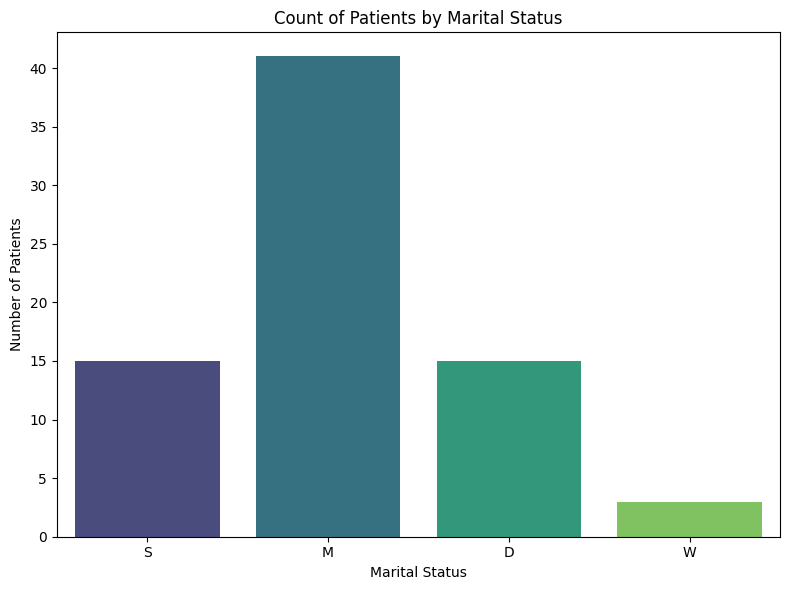

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df_drop, x='MARITAL', palette='viridis')
plt.title('Count of Patients by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

# **Data Analysis**

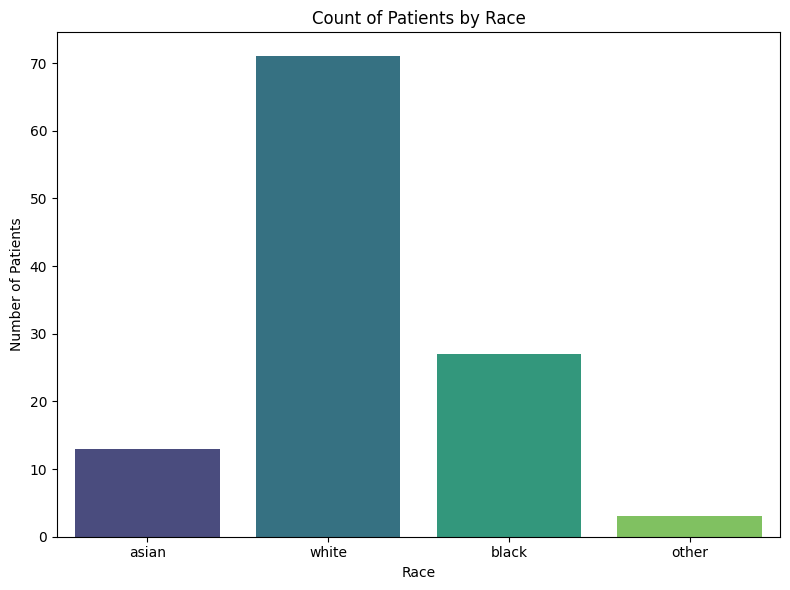

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df_drop, x='RACE', palette='viridis')
plt.title('Count of Patients by Race')
plt.xlabel('Race')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

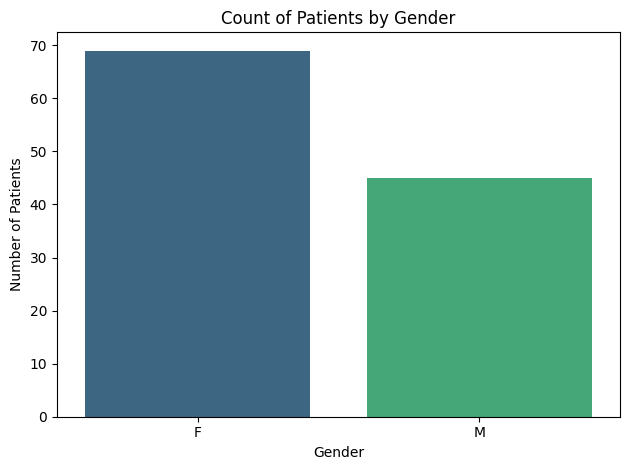

In [ ]:
sns.countplot(data=df_drop, x='GENDER', palette='viridis')
plt.title('Count of Patients by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

In [ ]:
df_drop['STATUS'] = df_drop['DEATHDATE'].apply(lambda x: 'Dead' if pd.notnull(x) else 'Alive')
df_drop

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,MIDDLE,LAST,MAIDEN,MARITAL,RACE,...,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,LAT,LON,AGE,STATUS
0,f159ef6a-b14e-f0d0-64d9-e6326471ebba,1999-04-09,NaT,Ms.,Fredricka,,Torp,,NaN,asian,...,F,Woburn Massachusetts US,163 Boehm Quay,Boston,Massachusetts,Suffolk County,42.302772,-71.114749,27,Alive
1,e397be1e-75a5-eed7-7b52-0ca1a08142a4,1943-03-24,NaT,Ms.,Erica,Denise,Ebert,,S,white,...,F,Middleborough Massachusetts US,754 Bernier Lock,Boston,Massachusetts,Suffolk County,42.381605,-71.091440,83,Alive
2,fe18a907-778a-369b-27b5-848340110628,1981-06-18,NaT,Mr.,Quincy,Kevin,Ortiz,,S,black,...,M,Weston Massachusetts US,1071 Heidenreich Estate,Boston,Massachusetts,Suffolk County,42.243086,-71.073701,45,Alive
3,150e9cf6-cbf2-fea7-6314-f64c6998a4f9,1975-07-09,NaT,Mr.,Lon,Edwardo,Lind,,M,white,...,M,Athol Massachusetts US,655 Abbott Flat,Boston,Massachusetts,Suffolk County,42.250019,-71.020347,51,Alive
4,cf488449-0521-705c-487d-bc96f6cc38fc,1945-05-20,NaT,Mr.,Michale,Antonia,Bins,,S,white,...,M,Springfield Massachusetts US,612 Treutel Loaf Suite 98,Boston,Massachusetts,Suffolk County,42.374079,-71.109131,81,Alive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,a96b6dbb-5213-3a92-3d99-3b1b0b8c8a33,2015-11-12,NaT,NaN,Dorsey,,Gleichner,,NaN,white,...,M,Hamburg Hamburg DE,938 Turcotte Light,Boston,Massachusetts,Suffolk County,42.341885,-71.067611,11,Alive
110,1e40b50f-4b75-1e46-2e17-82e9ea8ef766,1999-03-30,NaT,Ms.,Brandee,Cheryle,Hansen,,NaN,black,...,F,Worcester Massachusetts US,982 Christiansen Light,Boston,Massachusetts,Suffolk County,42.306111,-71.038137,27,Alive
111,e3b9d34e-4fb5-1cf6-cad6-6c0e005431a1,1973-06-10,NaT,Mrs.,Dot,Adriana,Johns,Roberts,M,black,...,F,Lynn Massachusetts US,135 Langworth Bay Unit 18,Boston,Massachusetts,Suffolk County,42.341145,-71.062728,53,Alive
112,9ae89c82-1143-ceb3-9038-b54678161c2e,1965-12-12,NaT,Mr.,Andrea,Mauro,Hamill,,M,black,...,M,Holyoke Massachusetts US,921 Thompson Port,Boston,Massachusetts,Suffolk County,42.352567,-71.068216,61,Alive


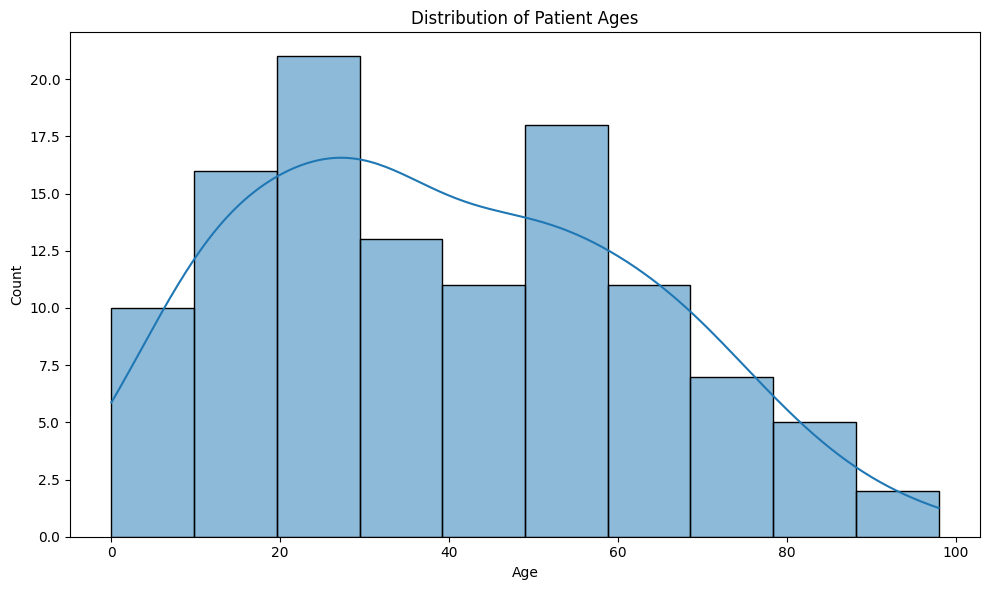

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df_drop['AGE'], bins=10, kde=True, palette='viridis')
plt.title('Distribution of Patient Ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

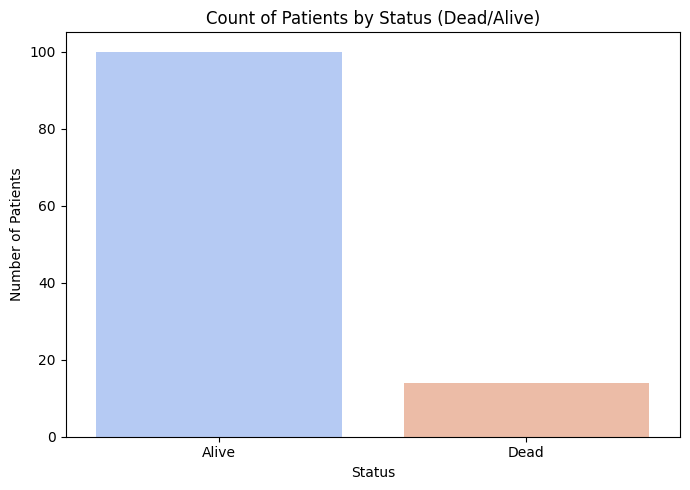

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df_drop, x='STATUS', palette='coolwarm')
plt.title('Count of Patients by Status (Dead/Alive)')
plt.xlabel('Status')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

## **Missing value handling**

In [ ]:
df_drop.isnull().sum()

,0
Id,0
BIRTHDATE,0
DEATHDATE,100
PREFIX,26
FIRST,0
MIDDLE,0
LAST,0
MAIDEN,0
MARITAL,40
RACE,0


In [ ]:
print("Unique prefixes: ", df_drop['PREFIX'].unique())
print("Unique genders: ", df_drop['GENDER'].unique())
print("Unique marital statuses: ", df_drop['MARITAL'].unique())

Unique prefixes:  ['Ms.' 'Mr.' 'Mrs.' nan]
Unique genders:  ['F' 'M']
Unique marital statuses:  [nan 'S' 'M' 'D' 'W']


In [ ]:
def get_ideal_prefix(row):
    gender = row['GENDER']
    marital_status = row['MARITAL']

    if gender == 'F':
        if marital_status == 'M' or marital_status == 'W':
            return 'Mrs.'
        else:
            return 'Ms.'
    elif gender == 'M':
        return 'Mr.'
    else:
        return None

def update_prefix_based_on_rules(row):
    current_prefix = row['PREFIX']
    ideal_prefix = get_ideal_prefix(row)

    if ideal_prefix is None:
        return current_prefix

    if pd.isna(current_prefix) or current_prefix != ideal_prefix:
        return ideal_prefix
    else:
        return current_prefix

df_drop_2_with_marital = df_drop.copy()
df_drop_2_with_marital['PREFIX_UPDATED'] = df_drop_2_with_marital.apply(update_prefix_based_on_rules, axis=1)

df_drop['PREFIX'] = df_drop_2_with_marital['PREFIX_UPDATED']
df_drop

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,MIDDLE,LAST,MAIDEN,MARITAL,RACE,...,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,LAT,LON,AGE,STATUS
0,f159ef6a-b14e-f0d0-64d9-e6326471ebba,1999-04-09,NaT,Ms.,Fredricka,,Torp,,NaN,asian,...,F,Woburn Massachusetts US,163 Boehm Quay,Boston,Massachusetts,Suffolk County,42.302772,-71.114749,27,Alive
1,e397be1e-75a5-eed7-7b52-0ca1a08142a4,1943-03-24,NaT,Ms.,Erica,Denise,Ebert,,S,white,...,F,Middleborough Massachusetts US,754 Bernier Lock,Boston,Massachusetts,Suffolk County,42.381605,-71.091440,83,Alive
2,fe18a907-778a-369b-27b5-848340110628,1981-06-18,NaT,Mr.,Quincy,Kevin,Ortiz,,S,black,...,M,Weston Massachusetts US,1071 Heidenreich Estate,Boston,Massachusetts,Suffolk County,42.243086,-71.073701,45,Alive
3,150e9cf6-cbf2-fea7-6314-f64c6998a4f9,1975-07-09,NaT,Mr.,Lon,Edwardo,Lind,,M,white,...,M,Athol Massachusetts US,655 Abbott Flat,Boston,Massachusetts,Suffolk County,42.250019,-71.020347,51,Alive
4,cf488449-0521-705c-487d-bc96f6cc38fc,1945-05-20,NaT,Mr.,Michale,Antonia,Bins,,S,white,...,M,Springfield Massachusetts US,612 Treutel Loaf Suite 98,Boston,Massachusetts,Suffolk County,42.374079,-71.109131,81,Alive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,a96b6dbb-5213-3a92-3d99-3b1b0b8c8a33,2015-11-12,NaT,Mr.,Dorsey,,Gleichner,,NaN,white,...,M,Hamburg Hamburg DE,938 Turcotte Light,Boston,Massachusetts,Suffolk County,42.341885,-71.067611,11,Alive
110,1e40b50f-4b75-1e46-2e17-82e9ea8ef766,1999-03-30,NaT,Ms.,Brandee,Cheryle,Hansen,,NaN,black,...,F,Worcester Massachusetts US,982 Christiansen Light,Boston,Massachusetts,Suffolk County,42.306111,-71.038137,27,Alive
111,e3b9d34e-4fb5-1cf6-cad6-6c0e005431a1,1973-06-10,NaT,Mrs.,Dot,Adriana,Johns,Roberts,M,black,...,F,Lynn Massachusetts US,135 Langworth Bay Unit 18,Boston,Massachusetts,Suffolk County,42.341145,-71.062728,53,Alive
112,9ae89c82-1143-ceb3-9038-b54678161c2e,1965-12-12,NaT,Mr.,Andrea,Mauro,Hamill,,M,black,...,M,Holyoke Massachusetts US,921 Thompson Port,Boston,Massachusetts,Suffolk County,42.352567,-71.068216,61,Alive


In [ ]:
df_drop.isnull().sum()

,0
Id,0
BIRTHDATE,0
DEATHDATE,100
PREFIX,0
FIRST,0
MIDDLE,0
LAST,0
MAIDEN,0
MARITAL,40
RACE,0


In [ ]:
df_drop_2 = df_drop.drop(columns=['MARITAL'], axis=1)
df_drop_2

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,MIDDLE,LAST,MAIDEN,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,LAT,LON,AGE,STATUS
0,f159ef6a-b14e-f0d0-64d9-e6326471ebba,1999-04-09,NaT,Ms.,Fredricka,,Torp,,asian,nonhispanic,F,Woburn Massachusetts US,163 Boehm Quay,Boston,Massachusetts,Suffolk County,42.302772,-71.114749,27,Alive
1,e397be1e-75a5-eed7-7b52-0ca1a08142a4,1943-03-24,NaT,Ms.,Erica,Denise,Ebert,,white,nonhispanic,F,Middleborough Massachusetts US,754 Bernier Lock,Boston,Massachusetts,Suffolk County,42.381605,-71.091440,83,Alive
2,fe18a907-778a-369b-27b5-848340110628,1981-06-18,NaT,Mr.,Quincy,Kevin,Ortiz,,black,nonhispanic,M,Weston Massachusetts US,1071 Heidenreich Estate,Boston,Massachusetts,Suffolk County,42.243086,-71.073701,45,Alive
3,150e9cf6-cbf2-fea7-6314-f64c6998a4f9,1975-07-09,NaT,Mr.,Lon,Edwardo,Lind,,white,hispanic,M,Athol Massachusetts US,655 Abbott Flat,Boston,Massachusetts,Suffolk County,42.250019,-71.020347,51,Alive
4,cf488449-0521-705c-487d-bc96f6cc38fc,1945-05-20,NaT,Mr.,Michale,Antonia,Bins,,white,nonhispanic,M,Springfield Massachusetts US,612 Treutel Loaf Suite 98,Boston,Massachusetts,Suffolk County,42.374079,-71.109131,81,Alive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,a96b6dbb-5213-3a92-3d99-3b1b0b8c8a33,2015-11-12,NaT,Mr.,Dorsey,,Gleichner,,white,nonhispanic,M,Hamburg Hamburg DE,938 Turcotte Light,Boston,Massachusetts,Suffolk County,42.341885,-71.067611,11,Alive
110,1e40b50f-4b75-1e46-2e17-82e9ea8ef766,1999-03-30,NaT,Ms.,Brandee,Cheryle,Hansen,,black,nonhispanic,F,Worcester Massachusetts US,982 Christiansen Light,Boston,Massachusetts,Suffolk County,42.306111,-71.038137,27,Alive
111,e3b9d34e-4fb5-1cf6-cad6-6c0e005431a1,1973-06-10,NaT,Mrs.,Dot,Adriana,Johns,Roberts,black,nonhispanic,F,Lynn Massachusetts US,135 Langworth Bay Unit 18,Boston,Massachusetts,Suffolk County,42.341145,-71.062728,53,Alive
112,9ae89c82-1143-ceb3-9038-b54678161c2e,1965-12-12,NaT,Mr.,Andrea,Mauro,Hamill,,black,nonhispanic,M,Holyoke Massachusetts US,921 Thompson Port,Boston,Massachusetts,Suffolk County,42.352567,-71.068216,61,Alive


# **Condition dataset**

In [ ]:
df_cond = pd.read_csv("conditions.csv")
df_cond

,START,STOP,PATIENT,ENCOUNTER,SYSTEM,CODE,DESCRIPTION
0,2016-11-16,2016-11-28,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-ca41-e746e7b9982a,http://snomed.info/sct,10509002,Acute bronchitis (disorder)
1,2016-11-25,2018-06-08,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-97a8-676ce3544751,http://snomed.info/sct,314529007,Medication review due (situation)
2,2017-06-02,NaN,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-589f-e2b248a9ddaf,http://snomed.info/sct,105531004,Housing unsatisfactory (finding)
3,2017-06-02,NaN,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-589f-e2b248a9ddaf,http://snomed.info/sct,224299000,Received higher education (finding)
4,2017-06-02,2018-06-08,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-589f-e2b248a9ddaf,http://snomed.info/sct,160903007,Full-time employment (finding)
...,...,...,...,...,...,...,...
4057,2026-01-09,NaN,6e7083a9-10f0-0bc5-da19-cd1d150b3b44,6e7083a9-10f0-0bc5-07a3-2b98cbffc59a,http://snomed.info/sct,422650009,Social isolation (finding)
4058,2026-03-27,2026-03-27,6e7083a9-10f0-0bc5-da19-cd1d150b3b44,6e7083a9-10f0-0bc5-f3a4-0e86218b14e3,http://snomed.info/sct,314529007,Medication review due (situation)
4059,2026-03-27,NaN,6e7083a9-10f0-0bc5-da19-cd1d150b3b44,6e7083a9-10f0-0bc5-f3a4-0e86218b14e3,http://snomed.info/sct,160903007,Full-time employment (finding)
4060,2026-03-27,NaN,6e7083a9-10f0-0bc5-da19-cd1d150b3b44,6e7083a9-10f0-0bc5-f3a4-0e86218b14e3,http://snomed.info/sct,73595000,Stress (finding)


In [ ]:
drop_columns = ["SYSTEM", "CODE"]

df_cond_drop = df_cond.drop(drop_columns, axis=1)
df_cond_drop.head()

,START,STOP,PATIENT,ENCOUNTER,DESCRIPTION
0,2016-11-16,2016-11-28,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-ca41-e746e7b9982a,Acute bronchitis (disorder)
1,2016-11-25,2018-06-08,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-97a8-676ce3544751,Medication review due (situation)
2,2017-06-02,NaN,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-589f-e2b248a9ddaf,Housing unsatisfactory (finding)
3,2017-06-02,NaN,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-589f-e2b248a9ddaf,Received higher education (finding)
4,2017-06-02,2018-06-08,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-589f-e2b248a9ddaf,Full-time employment (finding)


In [ ]:
patient_descriptions = df_cond.groupby('PATIENT')['DESCRIPTION'].nunique()

patients_with_multiple_descriptions = patient_descriptions[patient_descriptions > 1]

if not patients_with_multiple_descriptions.empty:
    print(f"Found {len(patients_with_multiple_descriptions)} patients with multiple unique descriptions.")
    print("Here are the top 5 patients with the most unique descriptions:")
    top_patients = patients_with_multiple_descriptions.nlargest(5).index.tolist()
    for patient_id in top_patients:
        print(f"\nPatient ID: {patient_id}")
        display(df_cond[df_cond['PATIENT'] == patient_id][['START', 'STOP', 'DESCRIPTION']].head())
else:
    print("No patients with multiple unique descriptions found.")

Found 113 patients with multiple unique descriptions.
Here are the top 5 patients with the most unique descriptions:

Patient ID: ade8e267-ba9f-809e-3859-748aca1a34c6


,START,STOP,DESCRIPTION
975,1975-10-08,NaN,Housing unsatisfactory (finding)
976,1975-10-08,NaN,Received higher education (finding)
977,1975-10-08,NaN,Has a criminal record (finding)
978,1981-02-18,NaN,Prediabetes (finding)
980,1992-08-05,NaN,Aortic valve stenosis (disorder)



Patient ID: 4c21eddb-c547-219f-3072-b58fed971528


,START,STOP,DESCRIPTION
1801,1951-03-22,NaN,Risk activity involvement (finding)
1802,1952-03-27,NaN,Housing unsatisfactory (finding)
1803,1952-03-27,NaN,Received higher education (finding)
1804,1952-03-27,NaN,Transport problem (finding)
1806,1962-04-12,NaN,Lack of access to transportation (finding)



Patient ID: 6e7083a9-10f0-0bc5-da19-cd1d150b3b44


,START,STOP,DESCRIPTION
3782,1946-08-09,NaN,Received higher education (finding)
3783,1946-08-09,NaN,Transport problem (finding)
3784,1947-08-15,NaN,Lack of access to transportation (finding)
3785,1959-08-28,NaN,Body mass index 30+ - obesity (finding)
3786,1961-10-26,NaN,Past pregnancy history of miscarriage (situation)



Patient ID: acc0a847-9db0-370e-6326-90de2da94e6f


,START,STOP,DESCRIPTION
3069,1974-11-01,NaN,Educated to high school level (finding)
3070,1974-11-01,NaN,Transport problem (finding)
3071,1975-11-07,NaN,Lack of access to transportation (finding)
3072,1983-03-19,NaN,Sepsis (disorder)
3073,1983-03-19,NaN,Septic shock (disorder)



Patient ID: 19756fea-b0b6-d2ba-cef2-f94bdc9b8b1d


,START,STOP,DESCRIPTION
2162,1955-07-13,NaN,History of appendectomy (situation)
2163,1965-03-08,NaN,Serving in military service (finding)
2164,1965-03-08,NaN,Received higher education (finding)
2165,1981-03-30,NaN,Body mass index 30+ - obesity (finding)
2166,1989-01-23,NaN,Smokes tobacco daily (finding)


In [ ]:
unique_descriptions = df_cond['DESCRIPTION'].unique()
print("Total unique descriptions:", len(unique_descriptions))
for desc in unique_descriptions:
    print(desc)

Total unique descriptions: 201
Acute bronchitis (disorder)
Medication review due (situation)
Housing unsatisfactory (finding)
Received higher education (finding)
Full-time employment (finding)
Stress (finding)
Gingivitis (disorder)
Not in labor force (finding)
Acute infective cystitis (disorder)
Social isolation (finding)
Reports of violence in the environment (finding)
Body mass index 40+ - severely obese (finding)
Body mass index 30+ - obesity (finding)
Prediabetes (finding)
Anemia (disorder)
Hyperlipidemia (disorder)
Past pregnancy history of miscarriage (situation)
Has a criminal record (finding)
Osteoporosis (disorder)
Part-time employment (finding)
Victim of intimate partner abuse (finding)
Fracture of bone (disorder)
Fracture of forearm (disorder)
Osteoporotic fracture of bone (disorder)
Traumatic or nontraumatic brain injury (disorder)
Chronic pain (finding)
Impacted molars (disorder)
Chronic intractable migraine without aura (disorder)
Educated to high school level (finding)
D

In [ ]:
descriptions_to_remove = [
    'Unemployed (finding)',
    'Homeless (finding)',
    'Housing unsatisfactory (finding)',
    'Received higher education (finding)',
    'Full-time employment (finding)',
    'Reports of violence in the environment (finding)'
    'Lack of access to transportation (finding)',
    'Transport problem (finding)',
    'Not in labor force (finding)',
    'Part-time employment (finding)',
    'Only received primary school education (finding)'
]

df_cond_drop = df_cond_drop[~df_cond_drop['DESCRIPTION'].isin(descriptions_to_remove)]

print(f"New shape: {df_cond_drop.shape}")
df_cond_drop

New shape: (3332, 5)


,START,STOP,PATIENT,ENCOUNTER,DESCRIPTION
0,2016-11-16,2016-11-28,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-ca41-e746e7b9982a,Acute bronchitis (disorder)
1,2016-11-25,2018-06-08,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-97a8-676ce3544751,Medication review due (situation)
5,2017-06-02,2018-06-08,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-589f-e2b248a9ddaf,Stress (finding)
6,2017-06-02,2017-06-16,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-589f-e2b248a9ddaf,Gingivitis (disorder)
8,2018-06-08,2018-06-22,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-e4b6-7d0279d83a61,Gingivitis (disorder)
...,...,...,...,...,...
4055,2026-01-09,2026-01-16,6e7083a9-10f0-0bc5-da19-cd1d150b3b44,6e7083a9-10f0-0bc5-07a3-2b98cbffc59a,Medication review due (situation)
4057,2026-01-09,NaN,6e7083a9-10f0-0bc5-da19-cd1d150b3b44,6e7083a9-10f0-0bc5-07a3-2b98cbffc59a,Social isolation (finding)
4058,2026-03-27,2026-03-27,6e7083a9-10f0-0bc5-da19-cd1d150b3b44,6e7083a9-10f0-0bc5-f3a4-0e86218b14e3,Medication review due (situation)
4060,2026-03-27,NaN,6e7083a9-10f0-0bc5-da19-cd1d150b3b44,6e7083a9-10f0-0bc5-f3a4-0e86218b14e3,Stress (finding)


# **Medication dataset**

In [ ]:
df_med = pd.read_csv("medications.csv")
df_med.head()

,START,STOP,PATIENT,PAYER,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,PAYER_COVERAGE,DISPENSES,TOTALCOST,REASONCODE,REASONDESCRIPTION
0,2016-11-16T21:04:45Z,2016-11-28T21:04:45Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,df166300-5a78-3502-a46a-832842197811,f159ef6a-b14e-f0d0-ca41-e746e7b9982a,313782,Acetaminophen 325 MG Oral Tablet,183.45,133.45,1,183.45,10509002.0,Acute bronchitis (disorder)
1,2017-03-18T04:48:11Z,2018-03-13T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,df166300-5a78-3502-a46a-832842197811,f159ef6a-b14e-f0d0-1119-acfb74d08eae,748856,{24 (drospirenone 3 MG / ethinyl estradiol 0.0...,229.32,179.32,12,2751.84,NaN,NaN
2,2018-03-13T04:48:11Z,2019-03-08T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,df166300-5a78-3502-a46a-832842197811,f159ef6a-b14e-f0d0-2d7e-ce16d51de8ad,831533,{28 (norethindrone 0.35 MG Oral Tablet) } Pack...,764.40,714.40,12,9172.80,NaN,NaN
3,2018-06-22T07:54:39Z,2018-06-22T07:54:39Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,df166300-5a78-3502-a46a-832842197811,f159ef6a-b14e-f0d0-5034-f6965d848e73,1535362,sodium fluoride 0.0272 MG/MG Oral Gel,129.94,79.94,1,129.94,66383009.0,Gingivitis (disorder)
4,2019-03-08T04:48:11Z,2020-03-02T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,df166300-5a78-3502-a46a-832842197811,f159ef6a-b14e-f0d0-3fc9-17ab83aab0ac,749762,{7 (ethinyl estradiol 0.01 MG Oral Tablet) / 8...,764.40,714.40,12,9172.80,NaN,NaN


In [ ]:
drop_columns = ["PAYER", "CODE", "BASE_COST", "PAYER_COVERAGE", "TOTALCOST", "REASONCODE"]

df_med_drop = df_med.drop(drop_columns, axis=1)
df_med_drop.head()

,START,STOP,PATIENT,ENCOUNTER,DESCRIPTION,DISPENSES,REASONDESCRIPTION
0,2016-11-16T21:04:45Z,2016-11-28T21:04:45Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-ca41-e746e7b9982a,Acetaminophen 325 MG Oral Tablet,1,Acute bronchitis (disorder)
1,2017-03-18T04:48:11Z,2018-03-13T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-1119-acfb74d08eae,{24 (drospirenone 3 MG / ethinyl estradiol 0.0...,12,NaN
2,2018-03-13T04:48:11Z,2019-03-08T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-2d7e-ce16d51de8ad,{28 (norethindrone 0.35 MG Oral Tablet) } Pack...,12,NaN
3,2018-06-22T07:54:39Z,2018-06-22T07:54:39Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-5034-f6965d848e73,sodium fluoride 0.0272 MG/MG Oral Gel,1,Gingivitis (disorder)
4,2019-03-08T04:48:11Z,2020-03-02T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-3fc9-17ab83aab0ac,{7 (ethinyl estradiol 0.01 MG Oral Tablet) / 8...,12,NaN


In [ ]:
df_med_drop.rename(columns={'DESCRIPTION': 'MEDICINE'}, inplace=True)
df_med_drop.rename(columns={'START': 'MED_START'}, inplace=True)
df_med_drop.rename(columns={'STOP': 'MED_STOP'}, inplace=True)
df_med_drop.shape

(4557, 7)

In [ ]:
unique_reason_descriptions = df_med_drop['REASONDESCRIPTION'].unique()
print("Total unique descriptions:", len(unique_reason_descriptions))
for desc in unique_reason_descriptions:
    print(desc)

Total unique descriptions: 41
Acute bronchitis (disorder)
nan
Gingivitis (disorder)
Acute infective cystitis (disorder)
Patient referral for dental care (procedure)
Hyperlipidemia (disorder)
Osteoporosis (disorder)
Pulmonary emphysema (disorder)
Streptococcal sore throat (disorder)
Essential hypertension (disorder)
Gout
Aortic valve stenosis (disorder)
Child attention deficit disorder (disorder)
Contact dermatitis (disorder)
Sepsis (disorder)
Viral sinusitis (disorder)
Chronic congestive heart failure (disorder)
Prediabetes (finding)
Malignant neoplasm of colon (disorder)
Malignant neoplasm of breast (disorder)
Alzheimer's disease (disorder)
Diabetes mellitus type 2 (disorder)
Anemia (disorder)
Osteoarthritis of knee (disorder)
Familial Alzheimer's disease of early onset (disorder)
Major depression  single episode (disorder)
Awaiting transplantation of kidney (situation)
History of renal transplant (situation)
Overlapping malignant neoplasm of colon (disorder)
Awaiting transplantation 

# **Condition + Medication Dataset**

In [ ]:
df_merged = pd.merge(
    df_cond_drop,
    df_med_drop,
    on=['PATIENT', 'ENCOUNTER'],
    how='left'
)

df_merged.isnull().sum()

,0
START,0
STOP,1170
PATIENT,0
ENCOUNTER,0
DESCRIPTION,0
MED_START,1722
MED_STOP,1999
MEDICINE,1722
DISPENSES,1722
REASONDESCRIPTION,3008


# **Allergies Dataset**

In [ ]:
df_allergies = pd.read_csv("allergies.csv")
df_allergies.head()

,START,STOP,PATIENT,ENCOUNTER,CODE,SYSTEM,DESCRIPTION,TYPE,CATEGORY,REACTION1,DESCRIPTION1,SEVERITY1,REACTION2,DESCRIPTION2,SEVERITY2
0,2020-02-10,NaN,77435a52-05ea-b1c8-3015-176f53b0e167,77435a52-05ea-b1c8-50a5-1da8f73295cc,609328004,SNOMED-CT,Allergic disposition (finding),allergy,environment,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-02-10,NaN,77435a52-05ea-b1c8-3015-176f53b0e167,77435a52-05ea-b1c8-50a5-1da8f73295cc,29046,RxNorm,Lisinopril,intolerance,medication,267036007.0,Dyspnea (finding),MODERATE,NaN,NaN,NaN
2,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,609328004,SNOMED-CT,Allergic disposition (finding),allergy,environment,NaN,NaN,NaN,NaN,NaN,NaN
3,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,84489001,SNOMED-CT,Mold (organism),allergy,environment,21626009.0,Cutaneous hypersensitivity (disorder),MILD,NaN,NaN,NaN
4,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,29046,RxNorm,Lisinopril,intolerance,medication,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
drop_columns = ["CODE", "SYSTEM", "REACTION1", "REACTION2"]

df_allergies_drop = df_allergies.drop(drop_columns, axis=1)
df_allergies_drop.head()

,START,STOP,PATIENT,ENCOUNTER,DESCRIPTION,TYPE,CATEGORY,DESCRIPTION1,SEVERITY1,DESCRIPTION2,SEVERITY2
0,2020-02-10,NaN,77435a52-05ea-b1c8-3015-176f53b0e167,77435a52-05ea-b1c8-50a5-1da8f73295cc,Allergic disposition (finding),allergy,environment,NaN,NaN,NaN,NaN
1,2020-02-10,NaN,77435a52-05ea-b1c8-3015-176f53b0e167,77435a52-05ea-b1c8-50a5-1da8f73295cc,Lisinopril,intolerance,medication,Dyspnea (finding),MODERATE,NaN,NaN
2,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,Allergic disposition (finding),allergy,environment,NaN,NaN,NaN,NaN
3,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,Mold (organism),allergy,environment,Cutaneous hypersensitivity (disorder),MILD,NaN,NaN
4,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,Lisinopril,intolerance,medication,NaN,NaN,NaN,NaN


In [ ]:
print(df_allergies_drop.shape)
df_allergies_drop.isnull().sum()

(106, 11)


,0
START,0
STOP,106
PATIENT,0
ENCOUNTER,0
DESCRIPTION,0
TYPE,0
CATEGORY,0
DESCRIPTION1,61
SEVERITY1,61
DESCRIPTION2,78


In [ ]:
df_allergies_drop['TYPE'].unique()
df_allergies_drop['CATEGORY'].unique()

array(['environment', 'medication', 'food'], dtype=object)

In [ ]:
df_allergies_drop.rename(columns={'DESCRIPTION': 'ALLERGY'}, inplace=True)
df_allergies_drop.rename(columns={'START': 'ALLERGY_START'}, inplace=True)
df_allergies_drop.rename(columns={'STOP': 'ALLERGY_STOP'}, inplace=True)

In [ ]:
df_allergies_drop.head()

,ALLERGY_START,ALLERGY_STOP,PATIENT,ENCOUNTER,ALLERGY,TYPE,CATEGORY,DESCRIPTION1,SEVERITY1,DESCRIPTION2,SEVERITY2
0,2020-02-10,NaN,77435a52-05ea-b1c8-3015-176f53b0e167,77435a52-05ea-b1c8-50a5-1da8f73295cc,Allergic disposition (finding),allergy,environment,NaN,NaN,NaN,NaN
1,2020-02-10,NaN,77435a52-05ea-b1c8-3015-176f53b0e167,77435a52-05ea-b1c8-50a5-1da8f73295cc,Lisinopril,intolerance,medication,Dyspnea (finding),MODERATE,NaN,NaN
2,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,Allergic disposition (finding),allergy,environment,NaN,NaN,NaN,NaN
3,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,Mold (organism),allergy,environment,Cutaneous hypersensitivity (disorder),MILD,NaN,NaN
4,1957-07-11,NaN,fa5a8262-cc49-d57c-bba3-9682885b38b7,fa5a8262-cc49-d57c-200f-d4ace284182f,Lisinopril,intolerance,medication,NaN,NaN,NaN,NaN


# **Observations Dataset**

In [ ]:
df_obs = pd.read_csv("observations.csv")
df_obs.head()

,DATE,PATIENT,ENCOUNTER,CATEGORY,CODE,DESCRIPTION,VALUE,UNITS,TYPE
0,2016-11-25T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-97a8-676ce3544751,vital-signs,8302-2,Body Height,162.9,cm,numeric
1,2016-11-25T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-97a8-676ce3544751,vital-signs,72514-3,Pain severity - 0-10 verbal numeric rating [Sc...,0.0,{score},numeric
2,2016-11-25T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-97a8-676ce3544751,vital-signs,29463-7,Body Weight,52.0,kg,numeric
3,2016-11-25T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-97a8-676ce3544751,vital-signs,39156-5,Body mass index (BMI) [Ratio],19.6,kg/m2,numeric
4,2016-11-25T04:48:11Z,f159ef6a-b14e-f0d0-64d9-e6326471ebba,f159ef6a-b14e-f0d0-97a8-676ce3544751,vital-signs,59576-9,Body mass index (BMI) [Percentile] Per age and...,29.1,%,numeric


In [ ]:
drop_columns = ["CODE"]

df_obs_drop = df_obs.drop(drop_columns, axis=1)
df_obs_drop.head()
df_obs_drop.shape

(75774, 8)

In [ ]:
df_obs_drop['CATEGORY'].unique()

array(['vital-signs', 'social-history', 'survey', 'procedure',
       'laboratory', nan, 'therapy', 'exam', 'imaging'], dtype=object)

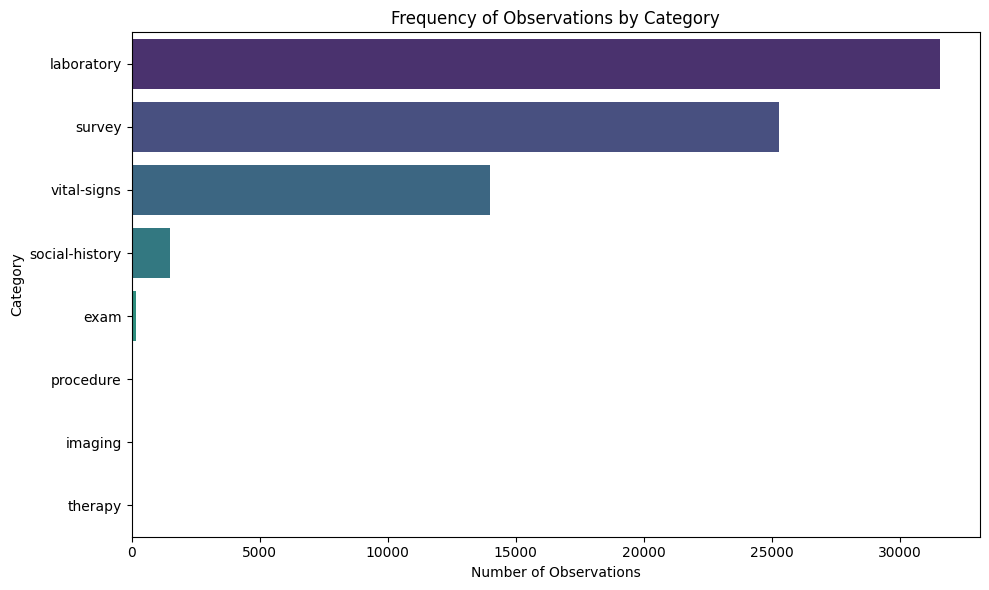

,Category,Observation_Count
0,laboratory,31553
1,survey,25264
2,vital-signs,13982
3,NaN,3135
4,social-history,1514
5,exam,192
6,procedure,74
7,imaging,42
8,therapy,18


In [ ]:
category_counts = df_obs_drop['CATEGORY'].value_counts(dropna=False).reset_index()
category_counts.columns = ['Category', 'Observation_Count']

plt.figure(figsize=(10, 6))
sns.barplot(data=category_counts, x='Observation_Count', y='Category', palette='viridis')
plt.title('Frequency of Observations by Category')
plt.xlabel('Number of Observations')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

display(category_counts)

In [ ]:
duplicates = df_obs_drop[df_obs_drop.duplicated(subset=['PATIENT', 'ENCOUNTER', 'DESCRIPTION'], keep=False)]

if not duplicates.empty:
    print(f"Found {len(duplicates)} duplicate observation entries.")
    display(duplicates.sort_values(by=['ENCOUNTER', 'DESCRIPTION']).head(10))
else:
    print("No duplicate readings for the same description within the same encounter were found.")

Found 6588 duplicate observation entries.


,DATE,PATIENT,ENCOUNTER,CATEGORY,DESCRIPTION,VALUE,UNITS,TYPE
48093,2020-01-11T09:57:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,laboratory,Diastolic Blood Pressure,104.0,mm[Hg],numeric
48095,2020-01-13T04:57:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,laboratory,Diastolic Blood Pressure,72.0,mm[Hg],numeric
48098,2020-01-18T11:27:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,laboratory,Diastolic Blood Pressure,41.4,mm[Hg],numeric
48090,2020-01-06T13:57:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,laboratory,Lactate [Moles/volume] in Blood,3.8,mmol/L,numeric
48092,2020-01-11T09:57:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,laboratory,Lactate [Moles/volume] in Blood,2.0,mmol/L,numeric
48097,2020-01-18T11:27:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,laboratory,Lactate [Moles/volume] in Blood,2.1,mmol/L,numeric
48094,2020-01-11T09:57:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,vital-signs,Systolic Blood Pressure,72.2,mm[Hg],numeric
48096,2020-01-13T04:57:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,vital-signs,Systolic Blood Pressure,125.0,mm[Hg],numeric
48099,2020-01-18T11:27:21Z,0aed8a17-2930-eba7-14a5-42dd2812fa65,0aed8a17-2930-eba7-f7b1-9f1180026c09,vital-signs,Systolic Blood Pressure,43.3,mm[Hg],numeric
44783,2017-04-04T10:11:29Z,0c0c81ea-4e91-f811-017d-213102a9a5ba,0c0c81ea-4e91-f811-afdf-f7e4625d2a04,laboratory,Calcium [Mass/volume] in Blood,9.2,mg/dL,numeric


In [ ]:
rag_categories = ['laboratory', 'vital-signs']

df_obs_rag = df_obs_drop[df_obs_drop['CATEGORY'].isin(rag_categories)]

top_rag_obs = df_obs_rag['DESCRIPTION'].value_counts().head(10)

print(f"Entries retained for RAG: {len(df_obs_rag)} (from {len(df_obs_drop)} total)")
display(top_rag_obs)

Entries retained for RAG: 45535 (from 75774 total)


,count
DESCRIPTION,
Pain severity - 0-10 verbal numeric rating [Score] - Reported,2058
Body Weight,1539
Diastolic Blood Pressure,1518
Systolic Blood Pressure,1518
Heart rate,1462
Respiratory rate,1462
Body Height,1450
Body mass index (BMI) [Ratio],1357
Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M,864


In [ ]:
df_obs_rag['DATE'] = pd.to_datetime(df_obs_rag['DATE'])

df_obs_rag_sorted = df_obs_rag.sort_values(by=['PATIENT', 'ENCOUNTER', 'DESCRIPTION', 'DATE'])

df_obs_latest = df_obs_rag_sorted.drop_duplicates(subset=['PATIENT', 'ENCOUNTER', 'DESCRIPTION'], keep='last')

print(f"Final RAG-ready dataset shape (Long format): {df_obs_latest.shape}")
display(df_obs_latest)

Final RAG-ready dataset shape (Long format): (42599, 8)


,DATE,PATIENT,ENCOUNTER,CATEGORY,DESCRIPTION,VALUE,UNITS,TYPE
11833,2023-05-18 03:43:48+00:00,01d9f90d-328e-bac9-af36-b721714cd7db,01d9f90d-328e-bac9-08c8-def5341d42e2,vital-signs,Body Height,173.5,cm,numeric
11835,2023-05-18 03:43:48+00:00,01d9f90d-328e-bac9-af36-b721714cd7db,01d9f90d-328e-bac9-08c8-def5341d42e2,vital-signs,Body Weight,86.0,kg,numeric
11836,2023-05-18 03:43:48+00:00,01d9f90d-328e-bac9-af36-b721714cd7db,01d9f90d-328e-bac9-08c8-def5341d42e2,vital-signs,Body mass index (BMI) [Ratio],28.6,kg/m2,numeric
11844,2023-05-18 03:43:48+00:00,01d9f90d-328e-bac9-af36-b721714cd7db,01d9f90d-328e-bac9-08c8-def5341d42e2,laboratory,Calcium [Mass/volume] in Blood,8.9,mg/dL,numeric
11848,2023-05-18 03:43:48+00:00,01d9f90d-328e-bac9-af36-b721714cd7db,01d9f90d-328e-bac9-08c8-def5341d42e2,laboratory,Carbon dioxide total [Moles/volume] in Blood,22.0,mmol/L,numeric
...,...,...,...,...,...,...,...,...
2011,2023-12-14 18:20:19+00:00,fe18a907-778a-369b-27b5-848340110628,fe18a907-778a-369b-ffbd-b871a12a97b9,laboratory,Platelet distribution width [Entitic volume] i...,15.1,fL,numeric
2010,2023-12-14 18:20:19+00:00,fe18a907-778a-369b-27b5-848340110628,fe18a907-778a-369b-ffbd-b871a12a97b9,laboratory,Platelets [#/volume] in Blood by Automated count,391.7,10*3/uL,numeric
1997,2023-12-14 18:20:19+00:00,fe18a907-778a-369b-27b5-848340110628,fe18a907-778a-369b-ffbd-b871a12a97b9,vital-signs,Respiratory rate,13.0,/min,numeric
1995,2023-12-14 18:20:19+00:00,fe18a907-778a-369b-27b5-848340110628,fe18a907-778a-369b-ffbd-b871a12a97b9,vital-signs,Systolic Blood Pressure,125.0,mm[Hg],numeric


In [ ]:
df_obs_latest['PATIENT'].nunique()

114

# **Merging all the datasets**

In [ ]:
import re, os, pandas as pd
from datetime import date

patients     = pd.read_csv("patients.csv")
conditions   = pd.read_csv("conditions.csv")
medications  = pd.read_csv("medications.csv")
allergies    = pd.read_csv("allergies.csv")
observations = pd.read_csv("observations.csv")
observations["DATE"] = pd.to_datetime(observations["DATE"], utc=True)

# ---------- cleaning helpers ----------
TAG = r"\s*\((finding|disorder|situation|procedure|substance|environment|event|morphologic abnormality|regime/therapy|record artifact)\)\s*$"
strip_tag  = lambda s: re.sub(TAG, "", str(s)).strip()
clean_name = lambda n: re.sub(r"\d+$", "", str(n)).strip()

NON_CLINICAL = ["medication review", "educat", "employ", "labor force", "social isolation",
                "stress", "risk activity", "violence", "housing", "homeless", "transport"]
is_clinical = lambda d: not any(k in d.lower() for k in NON_CLINICAL)

SHORT = {   # long LOINC names -> short names people actually type in queries
 "Body Height":"Height", "Body Weight":"Weight", "Body mass index (BMI) [Ratio]":"BMI",
 "Heart rate":"Heart rate", "Respiratory rate":"Resp rate",
 "Creatinine [Mass/volume] in Blood":"Creatinine",
 "Creatinine [Mass/volume] in Serum or Plasma":"Creatinine",
 "Glucose [Mass/volume] in Blood":"Glucose",
 "Hemoglobin A1c/Hemoglobin.total in Blood":"HbA1c",
 "Urea nitrogen [Mass/volume] in Blood":"BUN",
 "Sodium [Moles/volume] in Blood":"Sodium", "Potassium [Moles/volume] in Blood":"Potassium",
 "Hemoglobin [Mass/volume] in Blood":"Hemoglobin",
 "Cholesterol [Mass/volume] in Serum or Plasma":"Total cholesterol",
 "Cholesterol in LDL [Mass/volume] in Serum or Plasma by Direct assay":"LDL",
 "Cholesterol in HDL [Mass/volume] in Serum or Plasma":"HDL",
 "Triglyceride [Mass/volume] in Serum or Plasma":"Triglycerides",
}
BP = ("Systolic Blood Pressure", "Diastolic Blood Pressure")
obs = observations[observations["DESCRIPTION"].isin(list(SHORT) + list(BP))].copy()
obs["DAY"] = obs["DATE"].dt.strftime("%Y-%m-%d")

def fmt_val(v):
    try: return f"{float(v):g}"
    except: return str(v)
def fmt_unit(u):
    return {"mm[Hg]":"mmHg", "{score}":""}.get(u, "" if pd.isna(u) else u)
def d10(x): return str(x)[:10]

def build_doc(prow):
    pid  = prow["Id"]
    prefix = prow["PREFIX"] if pd.notna(prow["PREFIX"]) else ""
    name = f"{prefix} {clean_name(prow['FIRST'])} {clean_name(prow['LAST'])}".strip()
    tag  = f"{name} | ID {pid[:8]}"          # <-- repeated in every section
    age  = (date.today() - pd.to_datetime(prow["BIRTHDATE"]).date()).days // 365
    out  = [f"PATIENT SUMMARY | {tag}",
            f"DOB: {prow['BIRTHDATE']} | Age: {age} | Gender: {prow['GENDER']} | "
            f"Status: {'Deceased' if pd.notna(prow['DEATHDATE']) else 'Alive'}", ""]

    # conditions: one line each, split active vs resolved
    c = conditions[conditions["PATIENT"] == pid].copy()
    c = c[c["DESCRIPTION"].apply(is_clinical)]
    c["D"] = c["DESCRIPTION"].apply(strip_tag)
    active, resolved = [], []
    for d, g in c.groupby("D"):
        start = d10(g["START"].min())
        if g["STOP"].isna().any(): active.append((start, f"- {d} — since {start}"))
        else: resolved.append((start, f"- {d} — {start} to {d10(g['STOP'].max())}"))
    out += [f"ACTIVE CONDITIONS | {tag}"] + ([l for _, l in sorted(active)] or ["- None recorded."]) + [""]
    out += [f"RESOLVED CONDITIONS | {tag}"] + ([l for _, l in sorted(resolved)] or ["- None recorded."]) + [""]

    # medications: current vs past, deduplicated
    m = medications[medications["PATIENT"] == pid]
    cur, past = [], []
    cur_names = set(m[m["STOP"].isna()]["DESCRIPTION"])
    for d, g in m[m["STOP"].isna()].groupby("DESCRIPTION"):
        why = g["REASONDESCRIPTION"].dropna()
        cur.append(f"- {d} — since {d10(g['START'].min())}" + (f", for {strip_tag(why.iloc[0])}" if len(why) else ""))
    for d, g in m[m["STOP"].notna() & ~m["DESCRIPTION"].isin(cur_names)].groupby("DESCRIPTION"):
        past.append(f"- {d} — {d10(g['START'].min())} to {d10(g['STOP'].max())}")
    out += [f"CURRENT MEDICATIONS | {tag}"] + (cur or ["- None recorded."]) + [""]
    out += [f"PAST MEDICATIONS | {tag}"] + (past or ["- None recorded."]) + [""]

    # allergies: drop the placeholder row, keep category + reaction
    a = allergies[(allergies["PATIENT"] == pid) & (allergies["DESCRIPTION"] != "Allergic disposition (finding)")]
    al = []
    for _, r in a.iterrows():
        extra = f" — reaction: {strip_tag(r['DESCRIPTION1'])} ({r['SEVERITY1']})" if pd.notna(r["DESCRIPTION1"]) else ""
        al.append(f"- {strip_tag(r['DESCRIPTION'])} ({r['CATEGORY']} {r['TYPE']}){extra}")
    out += [f"ALLERGIES | {tag}"] + (al or ["- No known allergies."]) + [""]

    # latest values: SORT BY DATE FIRST, then take the last row per field
    po = obs[obs["PATIENT"] == pid].sort_values("DATE")
    latest = po[po["DESCRIPTION"].isin(SHORT)].copy()
    latest["S"] = latest["DESCRIPTION"].map(SHORT)
    latest = latest.groupby("S").tail(1)
    out.append(f"LATEST VITALS & LABS | {tag}")
    for _, r in latest.sort_values("S").iterrows():
        out.append(f"- {r['S']}: {fmt_val(r['VALUE'])} {fmt_unit(r['UNITS'])} ({r['DAY']})".replace("  ", " "))
    bp = po[po["DESCRIPTION"].isin(BP)]
    if len(bp):
        last_day = bp["DAY"].iloc[-1]; day = bp[bp["DAY"] == last_day]
        s = day[day["DESCRIPTION"] == BP[0]]["VALUE"]; d = day[day["DESCRIPTION"] == BP[1]]["VALUE"]
        if len(s) and len(d): out.append(f"- Blood pressure: {fmt_val(s.iloc[-1])}/{fmt_val(d.iloc[-1])} mmHg ({last_day})")
    out.append("")

    # visit history: ONE compact line per date, newest first
    out.append(f"VISIT HISTORY (vitals & labs by date) | {tag}")
    for day, g in sorted(po.groupby("DAY"), reverse=True):
        parts = [f"{SHORT[r.DESCRIPTION]} {fmt_val(r.VALUE)}{(' ' + fmt_unit(r.UNITS)) if fmt_unit(r.UNITS) else ''}"
                 for r in g.itertuples() if r.DESCRIPTION in SHORT]
        s = g[g["DESCRIPTION"] == BP[0]]["VALUE"]; d = g[g["DESCRIPTION"] == BP[1]]["VALUE"]
        if len(s) and len(d): parts.insert(0, f"BP {fmt_val(s.iloc[0])}/{fmt_val(d.iloc[0])} mmHg")
        out.append(f"[{tag}] {day}: " + "; ".join(parts))
    return "\n".join(out)

os.makedirs("source_documents", exist_ok=True)
for _, prow in patients.iterrows():
    open(f"source_documents/patient_{prow['Id'][:8]}.txt", "w").write(build_doc(prow))
print("done:", len(patients), "docs")

done: 114 docs


In [ ]:
import shutil
from google.colab import files

shutil.make_archive("source_documents", "zip", "source_documents")  # creates source_documents.zip
files.download("source_documents.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>